# Session 4: a small neural network on the yes/no question

**Course link:** Machine Learning Specialization, Course 2 Weeks 1–2 (neural networks, forward propagation, TensorFlow `Sequential` / `compile` / `fit`, ReLU, sigmoid, linear and softmax outputs, `from_logits`, Adam, backprop).

**Question:** does a small neural network beat Session 3's logistic regression at telling which consolidations are followed by weak TFP growth? Both on the original target and on the year-adjusted one.

**Choices made before fitting anything:**
- Same rows as Session 3: the 96 consolidation episodes (ΔCAPB ≥ 1.5 pp) in 24 countries. Same inputs: ΔCAPB and the four lagged controls, z-scored on the training countries only, with inflation capped at ±30 %.
- Same two targets: "weak" = TFP growth from t−1 to t+2 below the median of the training countries (original), or below the median of the training countries *in the same year* (year-adjusted).
- The network: 5 inputs → one hidden layer with ReLU → one output unit with a linear activation, trained with `BinaryCrossentropy(from_logits=True)` and Adam (learning rate 0.01, 500 full-batch steps).
- Kept tiny, with L2 regularization. The number of hidden units (2, 4 or 8) and λ (0.3, 1, 3 or 10) are chosen on the training countries only. (A check on the training countries showed that λ = 10 already shrinks the network to an almost flat guess, so larger values add nothing.)
- Logistic regression runs side by side, with λ chosen the same way.
- The same three unseen-country tests as Session 3: the six hidden countries, every country hidden in turn, and 500 random sets of six.
- The same baseline: always predict the most common training answer (for log loss: the training share of "weak").
- Random seeds are fixed. Section 9 shows how much the results move when the seed changes.
- Optional extra (section 10): three classes (weak / middle / strong growth) with a softmax-style output.

**Runtime:** about 25 minutes on a laptop, longer in Colab. Most of it is choosing the hidden units and λ again inside every round.

In [1]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (fill these in before running; to hide the saved results first, use Edit → Clear all outputs)

1. How many parameters (weights and biases) does a network with 5 inputs, 4 hidden units and 1 output have?
2. Compared with about 70 training episodes, is that a lot or a little?
3. On the six hidden countries, will the network beat logistic regression? With every country hidden in turn?
4. Which hidden-layer size (2 / 4 / 8) and which λ (0.3 / 1 / 3 / 10) will be chosen most often?
5. How much will the network's results change if only the random seed changes?
6. Three classes (weak / middle / strong): will the network beat always guessing the most common class?

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"           # hide TensorFlow's start-up messages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.losses import BinaryCrossentropy, SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import L2
from sklearn.linear_model import LogisticRegression

tf.config.experimental.enable_op_determinism()      # same seed -> same result
tf.get_logger().setLevel("ERROR")                     # hide repeated retracing warnings
pd.set_option("display.width", 160)
df = pd.read_csv(DATA_URL)
print("TensorFlow", tf.__version__, "| panel", df.shape)

TensorFlow 2.20.0 | panel (780, 22)


## 1. The same sample and targets as Session 3

`make_split` builds both targets with the cut-offs from the **training countries only**, recomputed every time. It also builds the three-class target for section 10 (cut at the training countries' thirds).

In [3]:
COUNTRY, YEAR, DCAPB, TFP = "country", "year", "dcapb_main", "tfp"
H, CAP = 2, 30
CONTROLS_RAW = ["gdp_growth", "debt_gdp", "inflation", "trade_open"]
CONTROLS = [c + "_lag1" for c in CONTROLS_RAW]
INPUTS = [DCAPB] + CONTROLS

def add_columns(frame, cap=CAP):
    d = frame.sort_values([COUNTRY, YEAR]).copy()
    d["inflation"] = d["inflation"].clip(-cap, cap)
    d["log_tfp"] = np.log(d[TFP])
    d["growth"] = 100 * (d.groupby(COUNTRY)["log_tfp"].shift(-H) - d.groupby(COUNTRY)["log_tfp"].shift(1))
    for raw, lagged in zip(CONTROLS_RAW, CONTROLS):
        d[lagged] = d.groupby(COUNTRY)[raw].shift(1)
    return d[[COUNTRY, YEAR, DCAPB, "growth"] + CONTROLS].dropna().reset_index(drop=True)

rows = add_columns(df)

def make_split(hidden, frame=rows, by_year=False):
    tr_all = frame[~frame[COUNTRY].isin(hidden)]
    if by_year:                                          # one cut-off per year
        g = tr_all.groupby(YEAR)["growth"]
        median, low, high = g.median(), g.quantile(1 / 3), g.quantile(2 / 3)
    else:
        median, low, high = (tr_all["growth"].median(), tr_all["growth"].quantile(1 / 3), tr_all["growth"].quantile(2 / 3))
    tr = tr_all[tr_all[DCAPB] >= 1.5].copy()
    te = frame[frame[COUNTRY].isin(hidden) & (frame[DCAPB] >= 1.5)].copy()
    for d in (tr, te):
        cut = (lambda s: d[YEAR].map(s)) if by_year else (lambda s: s)
        d["weak"] = (d["growth"] < cut(median)).astype(float)
        d["third"] = np.where(d["growth"] < cut(low), 0, np.where(d["growth"] < cut(high), 1, 2))   # 0 weak, 1 middle, 2 strong
    return tr, te

episodes, _ = make_split([])
TEST_COUNTRIES = ["Belgium", "Greece", "Lithuania", "Malta", "Slovakia", "Spain"]   # same six as Sessions 1-3 (seed 42)
TARGETS = {"Original": False, "Year-adjusted": True}
print(f"{len(episodes)} episodes in {episodes[COUNTRY].nunique()} countries")
for name, by_year in TARGETS.items():
    tr, te = make_split(TEST_COUNTRIES, by_year=by_year)
    print(f"{name}: {len(tr)} training and {len(te)} hidden-country episodes, share weak {tr['weak'].mean():.2f} / {te['weak'].mean():.2f}")

96 episodes in 24 countries
Original: 71 training and 25 hidden-country episodes, share weak 0.54 / 0.40
Year-adjusted: 71 training and 25 hidden-country episodes, share weak 0.55 / 0.40


## 2. The network, and how many parameters it has

**Course link:** Week 1 (layers, neurons, forward propagation, `Sequential`) and Week 2 (ReLU, linear output with `from_logits=True`, `BinaryCrossentropy`, Adam).

- The hidden layer has a few ReLU units: each one is max(0, w·x + b). The output unit is linear, so it gives z = w·a + b. The sigmoid is applied inside the loss (`from_logits=True`), which is more accurate, and again when we want a probability.
- **L2 regularization** is the same idea as λ in Course 1, applied to the weights of both layers (not the biases). Keras adds `l2 · Σw²` to the *average* loss, so the course's λ/(2m)·Σw² means `l2 = λ / (2m)`.
- **Adam** is gradient descent that adapts the step size for each weight by itself.
- **Speed trick:** all training rows are one batch, and the data is repeated 500 times inside one call to `fit` (`steps_per_execution`). That gives exactly the same 500 Adam steps as `epochs=500`, but runs several times faster. Section 3 checks that.

In [4]:
STEPS, LEARNING_RATE = 500, 0.01

def build_nn(units, lam, m, n_out=1):
    l2 = lam / (2 * m)                                   # course λ/(2m)·Σw²  ->  Keras l2·Σw²
    return Sequential([
        Input(shape=(len(INPUTS),)),
        Dense(units, activation="relu", kernel_regularizer=L2(l2)),
        Dense(n_out, activation="linear", kernel_regularizer=L2(l2)),
    ])

def train_nn(X, y, units, lam, seed=0, n_out=1):
    tf.keras.utils.set_random_seed(seed)                 # fixes the random starting weights
    model = build_nn(units, lam, len(X), n_out)
    loss = BinaryCrossentropy(from_logits=True) if n_out == 1 else SparseCategoricalCrossentropy(from_logits=True)
    model.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss=loss, steps_per_execution=STEPS)
    model.fit(np.tile(X, (STEPS, 1)), np.tile(y, STEPS), batch_size=len(X), epochs=1, shuffle=False, verbose=0)
    return model

m_train = len(make_split(TEST_COUNTRIES)[0])
example = build_nn(4, 10, m_train)
example.summary()
pd.DataFrame({units: {"parameters": build_nn(units, 10, m_train).count_params(), "training episodes": m_train,
                      "parameters per episode": round(build_nn(units, 10, m_train).count_params() / m_train, 2)}
              for units in (2, 4, 8)}).T.rename_axis("hidden units")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 4)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29 (116.00 B)

 Trainable params: 29 (116.00 B)

 Non-trainable params: 0 (0.00 B)

,parameters,training episodes,parameters per episode
hidden units,,,
2,15.0,71.0,0.21
4,29.0,71.0,0.41
8,57.0,71.0,0.80


## 3. Check the training: the learning curve, and the speed trick

The usual way, `fit(..., epochs=500)`, gives a learning curve. The fast version must end with exactly the same weights. Then a check that 500 steps are enough.

Largest weight difference between epochs=500 and the fast version: 0.0e+00


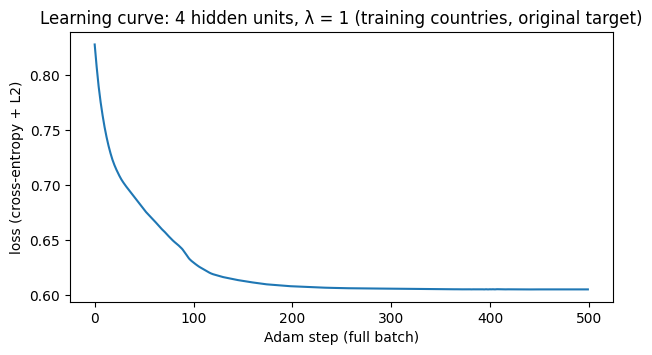

Loss after 100 steps 0.6305, after 500 steps 0.6054


8 units, λ = 0.3: loss after 500 steps 0.4468, after 2000 steps 0.4449


In [5]:
tr, te = make_split(TEST_COUNTRIES)
mu, sd = tr[INPUTS].mean(), tr[INPUTS].std(ddof=0)
X_tr = ((tr[INPUTS] - mu) / sd).to_numpy("float32")
y_tr = tr["weak"].to_numpy("float32")

tf.keras.utils.set_random_seed(0)
slow = build_nn(4, 1, len(X_tr))
slow.compile(optimizer=Adam(learning_rate=LEARNING_RATE), loss=BinaryCrossentropy(from_logits=True))
history = slow.fit(X_tr, y_tr, epochs=STEPS, batch_size=len(X_tr), shuffle=False, verbose=0)
fast = train_nn(X_tr, y_tr, 4, 1, seed=0)
gap = max(np.abs(a - b).max() for a, b in zip(slow.get_weights(), fast.get_weights()))
print(f"Largest weight difference between epochs=500 and the fast version: {gap:.1e}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(history.history["loss"])
ax.set_title("Learning curve: 4 hidden units, λ = 1 (training countries, original target)")
ax.set_xlabel("Adam step (full batch)"); ax.set_ylabel("loss (cross-entropy + L2)"); plt.show()
print(f"Loss after 100 steps {history.history['loss'][99]:.4f}, after 500 steps {history.history['loss'][-1]:.4f}")

# Are 500 steps enough? Compare with 2000 steps for the least regularized, largest network
STEPS = 2000
longer = train_nn(X_tr, y_tr, 8, 0.3, seed=0)
STEPS = 500
shorter = train_nn(X_tr, y_tr, 8, 0.3, seed=0)
print(f"8 units, λ = 0.3: loss after 500 steps {shorter.evaluate(X_tr, y_tr, verbose=0):.4f}, after 2000 steps {longer.evaluate(X_tr, y_tr, verbose=0):.4f}")

## 4. Fitting both models, and choosing their settings on the training countries only

- `fit_predict` trains logistic regression or the network on the training episodes and returns chances for other episodes. Logistic regression uses scikit-learn with C = 1/λ, which matched my own gradient descent in Session 3.
- `choose_settings` splits the **training** countries into 4 groups. It trains on 3 groups, scores the 4th, and repeats so each group is scored once. The setting with the lowest log loss wins. Only the left-out training countries are ever scored, never the hidden ones (the Session 3 leak). Course 2 Week 3 calls this *cross-validation*. Leaving one country out at a time, as in Session 3, would take about 5 times longer with the network.

In [6]:
GRIDS = {"logistic regression": [0, 0.1, 1, 10, 100],
         "neural network": [(units, lam) for units in (2, 4, 8) for lam in (0.3, 1, 3, 10)],
         "neural network, 3 classes": [(units, lam) for units in (2, 4, 8) for lam in (0.3, 1, 3, 10)]}
TARGET_COL = {"logistic regression": "weak", "neural network": "weak", "neural network, 3 classes": "third"}

def log_loss(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    if p.ndim == 1:
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
    return -np.mean(np.log(p[np.arange(len(y)), y.astype(int)]))

def fit_predict(kind, setting, tr, te, seed=0):
    mu, sd = tr[INPUTS].mean(), tr[INPUTS].std(ddof=0)             # scaling from the training countries only
    X_tr = ((tr[INPUTS] - mu) / sd).to_numpy("float32")
    X_te = ((te[INPUTS] - mu) / sd).to_numpy("float32")
    y = tr[TARGET_COL[kind]].to_numpy()
    if kind == "logistic regression":
        model = LogisticRegression(penalty=None, max_iter=10000) if setting == 0 else LogisticRegression(C=1 / setting, max_iter=10000)
        return model.fit(X_tr, y).predict_proba(X_te)[:, 1]
    units, lam = setting
    if kind == "neural network":
        model = train_nn(X_tr, y.astype("float32"), units, lam, seed)
        return tf.sigmoid(model(X_te, training=False)).numpy().ravel()
    model = train_nn(X_tr, y.astype("int32"), units, lam, seed, n_out=3)
    return tf.nn.softmax(model(X_te, training=False)).numpy()

def inner_groups(countries, k=4):
    c = sorted(countries)
    np.random.default_rng(0).shuffle(c)
    return [c[i::k] for i in range(k)]

def choose_settings(kind, hidden, frame=rows, by_year=False, seed=0):
    train_countries = [c for c in frame[COUNTRY].unique() if c not in hidden]
    scores = {}
    for setting in GRIDS[kind]:
        ys, ps = [], []
        for group in inner_groups(train_countries):
            tr, te = make_split(list(hidden) + group, frame, by_year)
            te = te[te[COUNTRY].isin(group)]                       # score only the left-out training countries
            if len(te):
                ps.append(fit_predict(kind, setting, tr, te, seed)); ys.append(te[TARGET_COL[kind]].to_numpy())
        scores[setting] = log_loss(np.concatenate(ps), np.concatenate(ys))
    return min(scores, key=scores.get), scores

def scores(y, p, prior):
    # prior = the simple guess: the training share of "weak" (2 classes) or of each class (3 classes)
    if p.ndim == 1:
        guess_p, pred, guess_pred = np.full(len(y), prior), (p >= 0.5).astype(float), float(prior >= 0.5)
    else:
        guess_p, pred, guess_pred = np.tile(prior, (len(y), 1)), p.argmax(axis=1), int(np.argmax(prior))
    return {"log loss": log_loss(p, y), "baseline log loss": log_loss(guess_p, y),
            "accuracy": np.mean(pred == y), "baseline accuracy": np.mean(guess_pred == y)}

def prior_of(kind, tr):
    if kind == "neural network, 3 classes":
        return np.bincount(tr["third"], minlength=3) / len(tr)
    return tr["weak"].mean()

## 5. The six hidden countries

In [7]:
MODELS = ["logistic regression", "neural network"]
six, chosen = [], {}
for target, by_year in TARGETS.items():
    tr, te = make_split(TEST_COUNTRIES, by_year=by_year)
    for kind in MODELS:
        setting, _ = choose_settings(kind, TEST_COUNTRIES, by_year=by_year)
        chosen[(target, kind)] = setting
        s = scores(te["weak"].to_numpy(), fit_predict(kind, setting, tr, te), prior_of(kind, tr))
        six.append({"target": target, "model": kind, "chosen (λ, or units and λ)": str(setting),
                    **{k: round(v, 3) for k, v in s.items()},
                    "log loss improvement %": round(100 * (1 - s["log loss"] / s["baseline log loss"]), 1)})
six = pd.DataFrame(six).set_index(["target", "model"])
six

chosen (λ, or units and λ)  log loss  baseline log loss  accuracy  baseline accuracy  log loss improvement %
target        model                                                                                                                           
Original      logistic regression                        100     0.695              0.710      0.40                0.4                     2.1
              neural network                         (8, 10)     0.705              0.710      0.40                0.4                     0.7
Year-adjusted logistic regression                        100     0.704              0.718      0.40                0.4                     2.0
              neural network                          (8, 3)     0.639              0.718      0.72                0.4                    10.9

## 6. Every country hidden in turn

For each of the 24 countries with episodes: hide it, choose the settings again on the other 23 (4 groups), train, and score the hidden country. The pooled numbers put all held-out episodes together. "Countries won" counts the rounds where the model's log loss beats the baseline. This cell is the slowest in the notebook.

In [8]:
def leave_one_out(kind, frame=rows, by_year=False, fixed=None, seed=0):
    per, ys, ps, priors = [], [], [], []
    for c in frame.loc[frame[DCAPB] >= 1.5, COUNTRY].unique():
        tr, te = make_split([c], frame, by_year)
        setting = fixed if fixed is not None else choose_settings(kind, [c], frame, by_year, seed)[0]
        p, y, prior = fit_predict(kind, setting, tr, te, seed), te[TARGET_COL[kind]].to_numpy(), prior_of(kind, tr)
        guess = np.full(len(y), prior) if p.ndim == 1 else np.tile(prior, (len(y), 1))
        ys.append(y); ps.append(p); priors.append(guess)
        per.append({COUNTRY: c, "episodes": len(y), "chosen": str(setting), "log loss": log_loss(p, y), "baseline": log_loss(guess, y)})
    y, p, guess = np.concatenate(ys), np.concatenate(ps), np.concatenate(priors)
    pred = (p >= 0.5).astype(float) if p.ndim == 1 else p.argmax(axis=1)
    guess_pred = (guess >= 0.5).astype(float) if guess.ndim == 1 else guess.argmax(axis=1)
    per = pd.DataFrame(per).set_index(COUNTRY)
    pooled = {"log loss": round(log_loss(p, y), 3), "baseline log loss": round(log_loss(guess, y), 3),
              "log loss improvement %": round(100 * (1 - log_loss(p, y) / log_loss(guess, y)), 1),
              "accuracy": round(np.mean(pred == y), 3), "baseline accuracy": round(np.mean(guess_pred == y), 3),
              "countries won": f"{int((per['log loss'] < per['baseline']).sum())} of {len(per)}"}
    return pooled, per

loo = {(target, kind): leave_one_out(kind, by_year=by_year) for target, by_year in TARGETS.items() for kind in MODELS}
pd.DataFrame({key: r[0] for key, r in loo.items()}).T

log loss baseline log loss log loss improvement % accuracy baseline accuracy countries won
Original      logistic regression     0.73             0.694                   -5.2    0.635              0.49      17 of 24
              neural network         0.763             0.694                  -10.0    0.573              0.49      14 of 24
Year-adjusted logistic regression    0.726               0.7                   -3.7    0.552             0.427      13 of 24
              neural network         0.713               0.7                   -1.9    0.552             0.427      12 of 24

In [9]:
# Which settings did the rounds choose?
for key, (pooled, per) in loo.items():
    print(f"{key[0]:>13}, {key[1]:<19}: " + ", ".join(f"{s} ×{n}" for s, n in per["chosen"].value_counts().items()))

     Original, logistic regression: 100 ×23, 10 ×1
     Original, neural network     : (8, 3) ×7, (4, 3) ×7, (8, 10) ×6, (4, 10) ×3, (2, 3) ×1
Year-adjusted, logistic regression: 100 ×22, 10 ×2
Year-adjusted, neural network     : (8, 10) ×8, (4, 3) ×5, (2, 3) ×3, (2, 1) ×2, (8, 3) ×2, (2, 10) ×2, (2, 0.3) ×1, (4, 10) ×1


## 7. 500 random sets of six hidden countries

As in Session 3, the settings are fixed at those chosen on the training countries in section 5, for speed. That makes this test slightly optimistic for both models (see the Session 3 placebo caveat).

In [10]:
def random_splits(kind, setting, by_year, n=500, seed=0):
    rng = np.random.default_rng(0)
    countries = rows.loc[rows[DCAPB] >= 1.5, COUNTRY].unique()
    ll, acc = [], []
    for _ in range(n):
        tr, te = make_split(rng.choice(countries, size=6, replace=False), by_year=by_year)
        s = scores(te[TARGET_COL[kind]].to_numpy(), fit_predict(kind, setting, tr, te, seed), prior_of(kind, tr))
        ll.append(100 * (1 - s["log loss"] / s["baseline log loss"])); acc.append(100 * (s["accuracy"] - s["baseline accuracy"]))
    return np.array(ll), np.array(acc)

splits = {(target, kind): random_splits(kind, chosen[(target, kind)], by_year)
          for target, by_year in TARGETS.items() for kind in MODELS}
pd.DataFrame({key: {"log loss better than baseline": f"{np.mean(ll > 0):.0%}", "median log loss gain %": round(np.median(ll), 1),
                    "accuracy better than baseline": f"{np.mean(acc > 0):.0%}", "median accuracy gain (points)": round(np.median(acc), 1)}
              for key, (ll, acc) in splits.items()}).T

log loss better than baseline median log loss gain % accuracy better than baseline median accuracy gain (points)
Original      logistic regression                           76%                    1.6                           60%                           4.7
              neural network                                71%                    1.2                           54%                           4.0
Year-adjusted logistic regression                           72%                    0.9                           55%                           3.8
              neural network                                49%                   -0.5                           67%                           7.7

## 8. Side by side

In [11]:
summary = {}
for target in TARGETS:
    for kind in MODELS:
        s, (pooled, _), (ll, acc) = six.loc[(target, kind)], loo[(target, kind)], splits[(target, kind)]
        summary[(target, kind)] = {
            "six hidden: log loss vs baseline": f"{s['log loss']:.3f} vs {s['baseline log loss']:.3f}",
            "six hidden: accuracy vs baseline": f"{s['accuracy']:.0%} vs {s['baseline accuracy']:.0%}",
            "each hidden in turn: log loss vs baseline": f"{pooled['log loss']:.3f} vs {pooled['baseline log loss']:.3f} ({pooled['log loss improvement %']:+.1f} %)",
            "each hidden in turn: accuracy vs baseline": f"{pooled['accuracy']:.1%} vs {pooled['baseline accuracy']:.1%}",
            "countries won": pooled["countries won"],
            "500 splits: log loss better": f"{np.mean(ll > 0):.0%} (median {np.median(ll):+.1f} %)"}
pd.DataFrame(summary)

Original                                      Year-adjusted                         
                                               logistic regression            neural network      logistic regression           neural network
six hidden: log loss vs baseline                    0.695 vs 0.710            0.705 vs 0.710           0.704 vs 0.718           0.639 vs 0.718
six hidden: accuracy vs baseline                        40% vs 40%                40% vs 40%               40% vs 40%               72% vs 40%
each hidden in turn: log loss vs baseline  0.730 vs 0.694 (-5.2 %)  0.763 vs 0.694 (-10.0 %)  0.726 vs 0.700 (-3.7 %)  0.713 vs 0.700 (-1.9 %)
each hidden in turn: accuracy vs baseline           63.5% vs 49.0%            57.3% vs 49.0%           55.2% vs 42.7%           55.2% vs 42.7%
countries won                                             17 of 24                  14 of 24                 13 of 24                 12 of 24
500 splits: log loss better                    76% (median +1.6 %)       71% (median +1.2 %)      72% (median +0.9 %)      49% (median -0.5 %)

## 9. How much does the random seed matter?

Logistic regression has one best answer, so its seed does not matter. A network starts from random weights, so a different seed can end somewhere else. Here the network is rerun with seeds 0–4:
- **Six hidden countries:** with the settings chosen again for each seed.
- **Every country hidden in turn:** with the settings fixed at the section 5 choice (choosing them again for every seed would take about 20 minutes more).

In [12]:
seed_rows = []
for target, by_year in TARGETS.items():
    tr, te = make_split(TEST_COUNTRIES, by_year=by_year)
    for seed in range(5):
        setting, _ = choose_settings("neural network", TEST_COUNTRIES, by_year=by_year, seed=seed)
        s = scores(te["weak"].to_numpy(), fit_predict("neural network", setting, tr, te, seed), tr["weak"].mean())
        pooled, _ = leave_one_out("neural network", by_year=by_year, fixed=chosen[(target, "neural network")], seed=seed)
        seed_rows.append({"target": target, "seed": seed, "chosen (six hidden)": str(setting),
                          "six hidden: log loss": round(s["log loss"], 3), "six hidden: accuracy": round(s["accuracy"], 3),
                          "each in turn (fixed settings): log loss gain %": pooled["log loss improvement %"],
                          "each in turn: accuracy": pooled["accuracy"], "countries won": pooled["countries won"]})
seeds = pd.DataFrame(seed_rows).set_index(["target", "seed"])
print(seeds.to_string())
print()
for target in TARGETS:
    t = seeds.loc[target]
    print(f"{target}: six-hidden log loss from {t['six hidden: log loss'].min():.3f} to {t['six hidden: log loss'].max():.3f}; "
          f"each-in-turn gain from {t['each in turn (fixed settings): log loss gain %'].min():+.1f} % to {t['each in turn (fixed settings): log loss gain %'].max():+.1f} %")

                   chosen (six hidden)  six hidden: log loss  six hidden: accuracy  each in turn (fixed settings): log loss gain %  each in turn: accuracy countries won
target        seed                                                                                                                                                      
Original      0                (8, 10)                 0.705                  0.40                                            -0.1                   0.604      15 of 24
              1                 (4, 3)                 0.659                  0.64                                            -0.3                   0.625      16 of 24
              2                 (4, 3)                 0.644                  0.68                                            -0.3                   0.625      15 of 24
              3                 (8, 3)                 0.657                  0.64                                             0.8                   0.625 

## 10. Optional extra: three classes with softmax

**Course link:** Week 2 (softmax, `SparseCategoricalCrossentropy(from_logits=True)`).

The year-adjusted target is split into three: weak (bottom third of the training countries in the same year), middle and strong (top third). The output layer now has 3 linear units, and softmax turns them into three chances that add up to 1. The baseline always predicts the most common training class, with the training class shares as its probabilities. Same tests, settings chosen on the training countries only (fixed for the 500 splits).

In [13]:
KIND3 = "neural network, 3 classes"
tr, te = make_split(TEST_COUNTRIES, by_year=True)
print("Class shares, training episodes (weak, middle, strong):", np.round(np.bincount(tr["third"], minlength=3) / len(tr), 2))
setting3, _ = choose_settings(KIND3, TEST_COUNTRIES, by_year=True)
s3 = scores(te["third"].to_numpy(), fit_predict(KIND3, setting3, tr, te), prior_of(KIND3, tr))
pooled3, per3 = leave_one_out(KIND3, by_year=True)
ll3, acc3 = random_splits(KIND3, setting3, by_year=True)
pd.Series({"chosen (units, λ)": str(setting3),
           "six hidden: log loss vs baseline": f"{s3['log loss']:.3f} vs {s3['baseline log loss']:.3f}",
           "six hidden: accuracy vs baseline": f"{s3['accuracy']:.0%} vs {s3['baseline accuracy']:.0%}",
           "each hidden in turn: log loss vs baseline": f"{pooled3['log loss']:.3f} vs {pooled3['baseline log loss']:.3f} ({pooled3['log loss improvement %']:+.1f} %)",
           "each hidden in turn: accuracy vs baseline": f"{pooled3['accuracy']:.1%} vs {pooled3['baseline accuracy']:.1%}",
           "countries won": pooled3["countries won"],
           "500 splits: log loss better": f"{np.mean(ll3 > 0):.0%} (median {np.median(ll3):+.1f} %)",
           "500 splits: accuracy better": f"{np.mean(acc3 > 0):.0%} (median {np.median(acc3):+.1f} points)"}, name="3 classes, year-adjusted")

Class shares, training episodes (weak, middle, strong): [0.34 0.35 0.31]


chosen (units, λ)                                             (8, 10)
six hidden: log loss vs baseline                       1.113 vs 1.117
six hidden: accuracy vs baseline                           20% vs 24%
each hidden in turn: log loss vs baseline     1.184 vs 1.116 (-6.1 %)
each hidden in turn: accuracy vs baseline              33.3% vs 35.4%
countries won                                                11 of 24
500 splits: log loss better                       57% (median +0.4 %)
500 splits: accuracy better                  64% (median +5.9 points)
Name: 3 classes, year-adjusted, dtype: object

# Learning log, Session 4 (9 Nov 2026)

**Course:** Machine Learning Specialization, Course 2 Weeks 1–2 (neural networks, forward propagation, TensorFlow `Sequential` / `compile` / `fit`, ReLU, sigmoid, linear and softmax outputs, `from_logits`, Adam, backprop)

**Question:** does a small neural network beat Session 3's logistic regression on the same yes/no target (TFP growth from t−1 to t+2 below the median), and on the year-adjusted one?

**Setup, decided before fitting:**
- Same rows, inputs and targets as Session 3: 96 consolidation episodes in 24 countries; ΔCAPB and the four lagged controls, z-scored on the training countries only; inflation capped at ±30 %.
- Network: 5 inputs → one ReLU hidden layer → one linear output unit, `BinaryCrossentropy(from_logits=True)`, Adam (learning rate 0.01), 500 full-batch steps. L2 on the weights of both layers, with Keras `l2 = λ/(2m)` so that λ means the same as in Course 1.
- The settings are chosen on the training countries only, by splitting them into 4 groups and scoring each left-out group (never the hidden countries). Logistic regression gets the same treatment.
  - Network: hidden units ∈ {2, 4, 8} and λ ∈ {0.3, 1, 3, 10}. A check on the training countries showed that λ = 10 already shrinks the network to an almost flat guess, so 100 was dropped.
  - Logistic regression: λ ∈ {0, 0.1, 1, 10, 100}.
- Same three tests and the same majority-class baseline as Session 3. Random seed 0 for the main results; seeds 0–4 to see how much they move.

**Checks**
- Size: 5 inputs and 2 / 4 / 8 hidden units give 15 / 29 / 57 parameters, against 71 training episodes (0.21 / 0.41 / 0.80 parameters per episode). Even the "tiny" 8-unit network has almost one parameter per episode.
- Speed trick: repeating the data 500 times inside one `fit` call (`steps_per_execution`) gives exactly the same weights as `epochs=500` (difference 0.0), about 6 times faster.
- 500 steps are enough: for the least regularized, largest network (8 units, λ = 0.3) the loss is 0.4468 after 500 steps and 0.4449 after 2000.
- With the 4-group tuning, logistic regression reproduces Session 3's original-target results exactly (six hidden 0.695 vs 0.710; each hidden in turn −5.2 %, 17 of 24). On the year-adjusted target it comes out a little worse than in Session 3 (−3.7 % instead of −2.5 %), because 2 rounds now choose λ = 10.

**Results**

| Test | Logistic regression, original | Neural network, original | Logistic regression, year-adjusted | Neural network, year-adjusted |
|---|---|---|---|---|
| Chosen on the six-hidden training countries | λ = 100 | 8 units, λ = 10 | λ = 100 | 8 units, λ = 3 |
| Six hidden: log loss vs baseline | 0.695 vs 0.710 | 0.705 vs 0.710 | 0.704 vs 0.718 | **0.639 vs 0.718** |
| Six hidden: accuracy vs baseline | 40 % vs 40 % | 40 % vs 40 % | 40 % vs 40 % | **72 % vs 40 %** |
| Each hidden in turn: log loss vs baseline | 0.730 vs 0.694 (−5.2 %) | 0.763 vs 0.694 (−10.0 %) | 0.726 vs 0.700 (−3.7 %) | 0.713 vs 0.700 (−1.9 %) |
| Each hidden in turn: accuracy vs baseline | 63.5 % vs 49.0 % | 57.3 % vs 49.0 % | 55.2 % vs 42.7 % | 55.2 % vs 42.7 % |
| Countries won | 17 of 24 | 14 of 24 | 13 of 24 | 12 of 24 |
| 500 random splits: log loss better | 76 % (median +1.6 %) | 71 % (median +1.2 %) | 72 % (median +0.9 %) | 49 % (median −0.5 %) |

- **The answer is no.** With every country hidden in turn, the network is worse than the baseline on both targets, and worse than logistic regression on the original target. In the random splits it wins less often than logistic regression.
- **The one bright spot is luck.** On the year-adjusted target the network looks clearly better on the six hidden countries (log loss 0.639, accuracy 72 %). But that is seed 0 on one split: with seeds 1–4 the same test gives 0.659 to 0.751, the fairer tests show no gain, and the random splits are a coin flip (49 %).
- **The network's settings jump around.** Across the 24 rounds the original-target network chose 5 different settings (8 or 4 units with λ = 3 most often), and the year-adjusted one chose 8 different settings. Logistic regression chose λ = 100 in 23 of 24 rounds (22 of 24 year-adjusted). When the best setting changes with every small change in the data, there is no stable pattern to find.

**How much the seed matters (network, seeds 0–4)**

| Target | Six hidden: log loss (settings chosen again per seed) | Each hidden in turn: log loss gain (settings fixed) | Countries won |
|---|---|---|---|
| Original | 0.644 to 0.705 | −0.4 % to +0.8 % | 15 or 16 of 24 |
| Year-adjusted | 0.639 to 0.751 | −5.9 % to +0.8 % | 11 to 13 of 24 |

- Changing only the seed moves the six-hidden log loss by up to 0.11, more than the gap between any model and the baseline. The seed even changes which settings get chosen. A single run of a network on this little data can look good or bad by chance.
- (With the settings fixed at the section 5 choice, every country hidden in turn gives −0.1 % for seed 0 on both targets, not the −10.0 % and −1.9 % above. Choosing the settings again in each round costs a lot, because the choice is unstable.)

**Optional extra: three classes (weak / middle / strong, year-adjusted)**
- The cut-offs are the thirds of the training countries' growth in the same year. Class shares in the training episodes are 34 / 35 / 31 %. Output: 3 linear units with softmax, `SparseCategoricalCrossentropy(from_logits=True)`. Chosen: 8 units, λ = 10.
- Six hidden: log loss 1.113 vs 1.117, accuracy 20 % vs 24 %. Each hidden in turn: 1.184 vs 1.116 (−6.1 %), accuracy 33.3 % vs 35.4 %, 11 of 24 countries. 500 splits: log loss better in 57 % (median +0.4 %).
- No gain: with three classes the network does not even beat always guessing the most common class.

**Main lessons**
- A more flexible model does not help when there is almost no signal. The network adds parameters, not information.
- With about 70 training rows, even a "tiny" network has nearly one parameter per row, and its settings and seed change the result more than the model beats the baseline by.
- Always report the seed spread for a network. One good seed on one split (72 % accuracy here) is exactly the kind of result that does not survive the fairer tests.
- Regularization pushes the network towards a flat guess, just as λ = 100 did for logistic regression: on this data the best a model can do is stay close to the baseline.
- This matches the learning note in CLAUDE.md: with a few hundred country-years, prefer simple models. ML still adds nothing reliable over the econometrics.

**Next:** Session 5, Course 2 Weeks 3–4: evaluating models (train / cross-validation / test, bias and variance), then decision trees, to test whether there is a large-consolidation threshold.